In [1]:
import os
import cv2
import json
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models

In [3]:
DATA_DIR = r"C:\Users\Lenovo\Desktop\KCGI Academics\Academics\Masters_Project\teaLeafBD_fastCrop_merged"

IMG_SIZE = 224
BATCH_SIZE = 32
SEED = 42

OUTPUT_DIR = "gradcam_examples"
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [4]:
import pandas as pd
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

rows = []

DATASET_PATH = r"C:\Users\Lenovo\Desktop\KCGI Academics\Academics\Masters_Project\teaLeafBD_fastCrop_merged" 

class_names = sorted([
    d for d in os.listdir(DATASET_PATH)
    if os.path.isdir(os.path.join(DATASET_PATH, d))
])

label2idx = {c:i for i,c in enumerate(class_names)}

for c in class_names:
    cdir = os.path.join(DATASET_PATH, c)

    for fn in os.listdir(cdir):
        if fn.lower().endswith(IMG_EXT):
            rows.append({
                "path": os.path.join(cdir, fn),
                "label": label2idx[c]
            })

df = pd.DataFrame(rows)

print(df.head())

                                                path  label
0  C:\Users\Lenovo\Desktop\KCGI Academics\Academi...      0
1  C:\Users\Lenovo\Desktop\KCGI Academics\Academi...      0
2  C:\Users\Lenovo\Desktop\KCGI Academics\Academi...      0
3  C:\Users\Lenovo\Desktop\KCGI Academics\Academi...      0
4  C:\Users\Lenovo\Desktop\KCGI Academics\Academi...      0


In [18]:
from sklearn.model_selection import train_test_split
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

In [21]:
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = tf.cast(img, tf.float32)

    return img, label

In [23]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
])

In [25]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (train_df["path"].values, train_df["label"].values)
)
val_ds = tf.data.Dataset.from_tensor_slices(
    (val_df["path"].values, val_df["label"].values)
)
test_ds = tf.data.Dataset.from_tensor_slices(
    (test_df["path"].values, test_df["label"].values)
)

In [27]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.map(load_image, num_parallel_calls=AUTOTUNE)
val_ds = val_ds.map(load_image, num_parallel_calls=AUTOTUNE)
test_ds = test_ds.map(load_image, num_parallel_calls=AUTOTUNE)

In [29]:
train_ds = train_ds.map(
    lambda x, y: (data_augmentation(x, training=True), y),
    num_parallel_calls=AUTOTUNE
)

In [31]:
from tensorflow.keras.applications.resnet50 import preprocess_input

train_ds = train_ds.map(
    lambda x, y: (preprocess_input(x), y),
    num_parallel_calls=AUTOTUNE
)

val_ds = val_ds.map(
    lambda x, y: (preprocess_input(x), y),
    num_parallel_calls=AUTOTUNE
)

test_ds = test_ds.map(
    lambda x, y: (preprocess_input(x), y),
    num_parallel_calls=AUTOTUNE
)

In [33]:
from tensorflow.keras.applications import ResNet50

base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = True

In [35]:
inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

x = base_model(inputs, training=True)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.4)(x)

outputs = layers.Dense(
    len(class_names),
    activation="softmax"
)(x)

model = models.Model(inputs, outputs)

In [37]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=3e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [39]:
model.load_weights("best_resnet50.keras")
print("Model Weights loaded successfully")

Model Weights loaded successfully


In [41]:
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_loss, test_acc = model.evaluate(test_ds)

print("Test Accuracy:", test_acc)

25/25 [==============================] - 219s 8s/step - loss: 0.2260 - accuracy: 0.9271
Test Accuracy: 0.927109956741333


In [67]:
last_conv_layer_name = "conv5_block3_out"

resnet_layer = model.get_layer("resnet50")

# Model from ResNet input to: last conv feature map + ResNet final feature map
resnet_grad_model = tf.keras.models.Model(
    inputs=resnet_layer.input,
    outputs=[
        resnet_layer.get_layer(last_conv_layer_name).output,
        resnet_layer.output
    ]
)

# Everything after ResNet50 in the outer model
resnet_index = [i for i, layer in enumerate(model.layers) if layer.name == "resnet50"][0]
classifier_layers = model.layers[resnet_index + 1:]

print("Classifier layers:", [layer.name for layer in classifier_layers])


Classifier layers: ['global_average_pooling2d_1', 'dropout_1', 'dense_1']


In [69]:
def make_gradcam_heatmap(img_array):
    """
    img_array must be raw RGB image batch with shape (1, 224, 224, 3), values 0-255.
    """
    img_array = tf.cast(img_array, tf.float32)

    # Apply same preprocessing before feeding into ResNet.
    preprocessed = tf.keras.applications.resnet50.preprocess_input(img_array)

    with tf.GradientTape() as tape:
        conv_outputs, resnet_output = resnet_grad_model(preprocessed)

        x = resnet_output
        for layer in classifier_layers:
            x = layer(x, training=False)

        predictions = x
        pred_index = tf.argmax(predictions[0])
        class_score = predictions[:, pred_index]

    grads = tape.gradient(class_score, conv_outputs)

    if grads is None:
        raise ValueError("Gradients are None. Check the Grad-CAM model connection.")

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]

    # Weighted sum across channels -> 7x7 heatmap
    heatmap = tf.reduce_sum(conv_outputs * pooled_grads, axis=-1)
    heatmap = tf.maximum(heatmap, 0)

    heatmap = heatmap.numpy()
    max_val = np.max(heatmap)
    if max_val > 0:
        heatmap = heatmap / max_val

    return heatmap


In [71]:
def save_gradcam_overlay(image_array, heatmap, save_path, alpha=0.4):
    """
    image_array: raw RGB image, shape (224,224,3), values 0-255.
    heatmap: Grad-CAM heatmap, usually 7x7.
    """
    img = image_array.astype("uint8")

    heatmap = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
    heatmap = np.uint8(255 * heatmap)

    heatmap_color = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)

    overlay = heatmap_color * alpha + img
    overlay = np.clip(overlay, 0, 255).astype("uint8")

    cv2.imwrite(save_path, cv2.cvtColor(overlay, cv2.COLOR_RGB2BGR))

    return overlay


In [73]:
examples_per_class = 2
saved_count = {class_name: 0 for class_name in class_names}

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)

    for i in range(images.shape[0]):
        true_idx = int(labels[i].numpy())
        pred_idx = int(np.argmax(preds[i]))

        true_class = class_names[true_idx]
        pred_class = class_names[pred_idx]
        confidence = float(np.max(preds[i]) * 100)

        if saved_count[true_class] >= examples_per_class:
            continue

        img = images[i].numpy().astype("uint8")
        img_array = np.expand_dims(img, axis=0)

        heatmap = make_gradcam_heatmap(img_array)

        safe_true = true_class.replace(" ", "_").replace("/", "_")
        safe_pred = pred_class.replace(" ", "_").replace("/", "_")

        file_name = f"{safe_true}_pred_{safe_pred}_{saved_count[true_class] + 1}_{confidence:.1f}.jpg"
        save_path = os.path.join(OUTPUT_DIR, file_name)

        save_gradcam_overlay(
            image_array=img,
            heatmap=heatmap,
            save_path=save_path
        )

        saved_count[true_class] += 1
        print(f"Saved: {save_path} | Confidence: {confidence:.2f}%")

    if all(count >= examples_per_class for count in saved_count.values()):
        break

print("Done generating Grad-CAM examples")
print(saved_count)


Saved: gradcam_examples\7._Healthy_leaf_pred_7._Healthy_leaf_1_99.8.jpg | Confidence: 99.78%
Saved: gradcam_examples\7._Healthy_leaf_pred_7._Healthy_leaf_2_95.8.jpg | Confidence: 95.81%
Saved: gradcam_examples\4._Helopeltis_pred_4._Helopeltis_1_95.3.jpg | Confidence: 95.27%
Saved: gradcam_examples\1._Tea_algal_leaf_spot_pred_1._Tea_algal_leaf_spot_1_83.6.jpg | Confidence: 83.57%
Saved: gradcam_examples\1._Tea_algal_leaf_spot_pred_1._Tea_algal_leaf_spot_2_99.0.jpg | Confidence: 98.98%
Saved: gradcam_examples\6._Green_mirid_bug_pred_6._Green_mirid_bug_1_100.0.jpg | Confidence: 100.00%
Saved: gradcam_examples\3._Gray_Blight_pred_3._Gray_Blight_1_99.9.jpg | Confidence: 99.90%
Saved: gradcam_examples\2._Brown_Blight_pred_2._Brown_Blight_1_99.9.jpg | Confidence: 99.88%
Saved: gradcam_examples\4._Helopeltis_pred_4._Helopeltis_2_100.0.jpg | Confidence: 100.00%
Saved: gradcam_examples\6._Green_mirid_bug_pred_6._Green_mirid_bug_2_99.9.jpg | Confidence: 99.87%
Saved: gradcam_examples\3._Gray_Blig

Saved files: 14


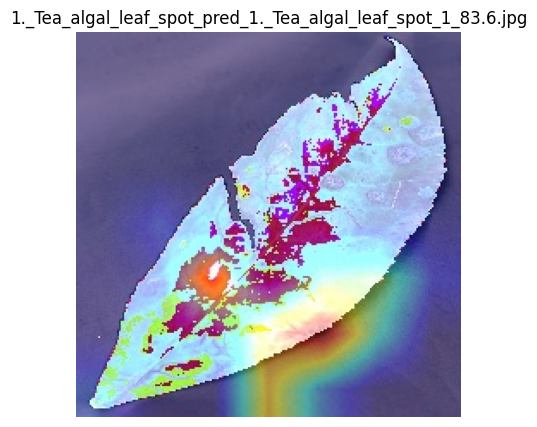

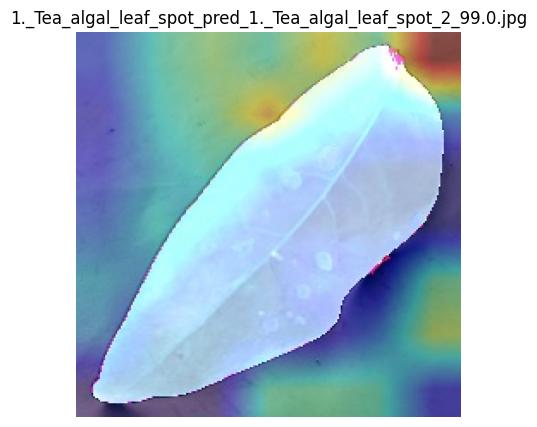

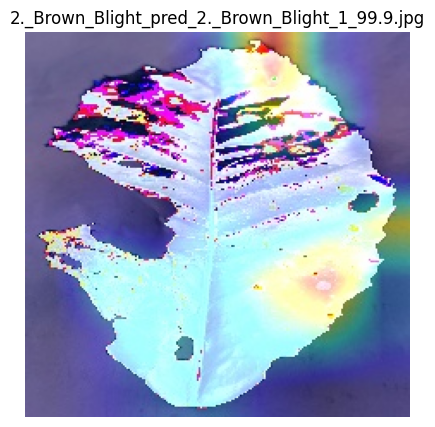

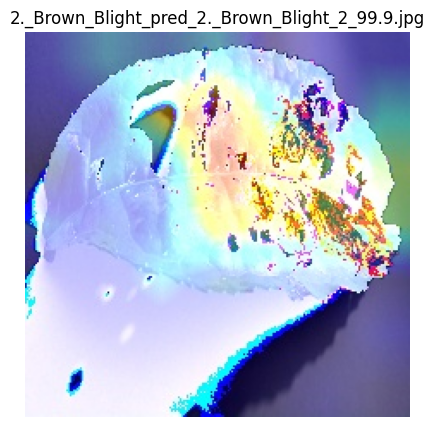

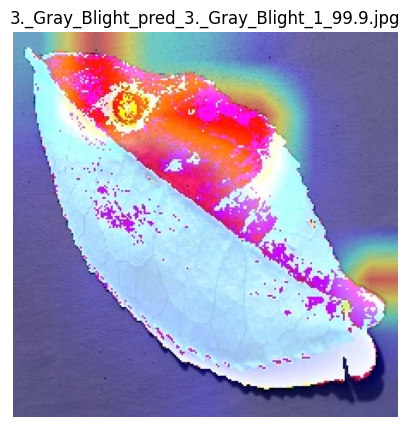

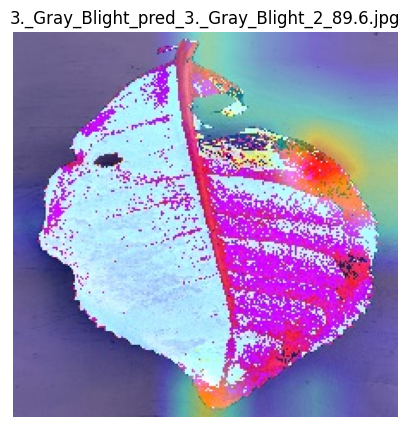

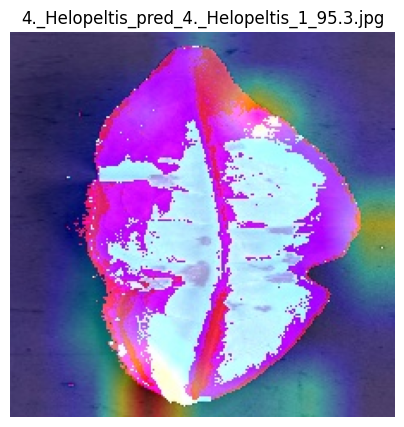

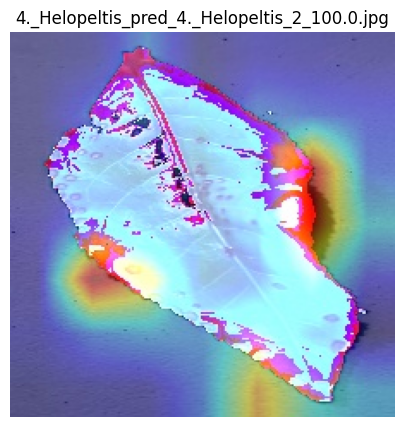

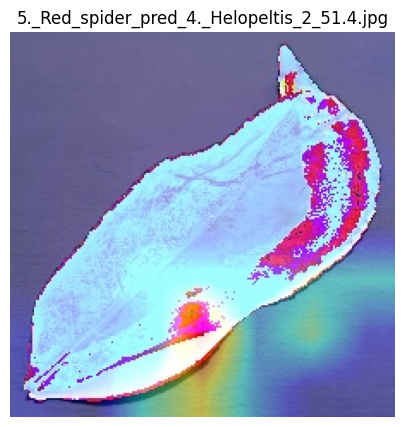

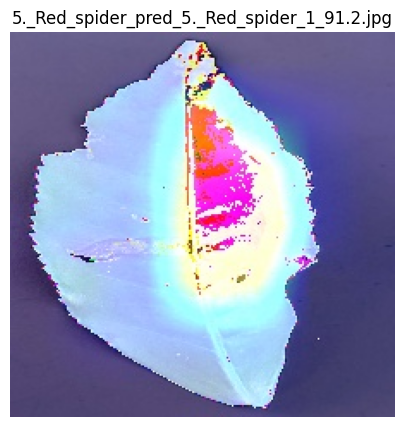

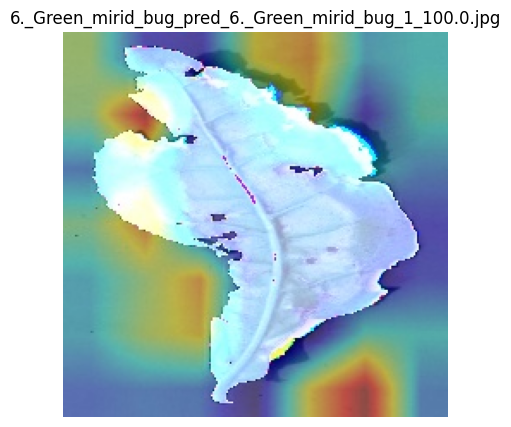

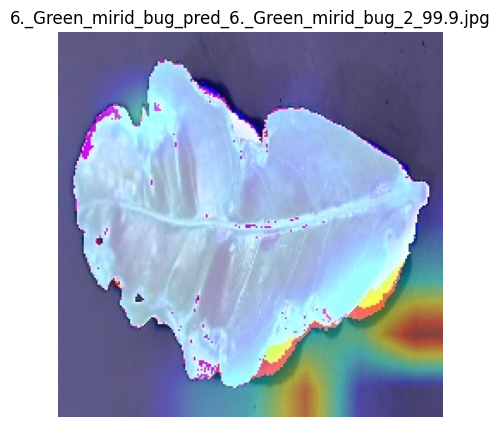

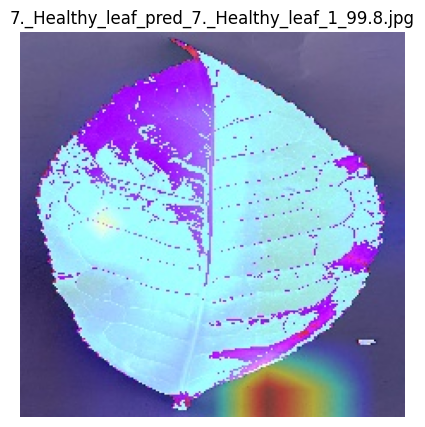

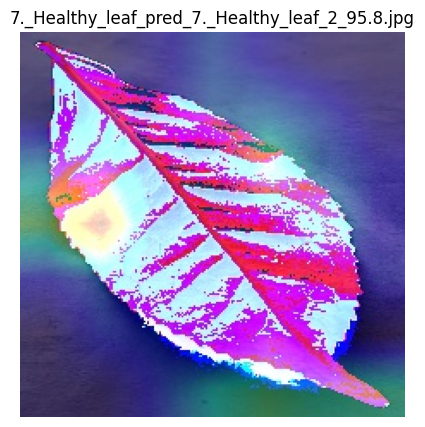

In [75]:
import glob

files = glob.glob(os.path.join(OUTPUT_DIR, "*.jpg"))
print("Saved files:", len(files))

for file in files:
    img = cv2.imread(file)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.title(os.path.basename(file))
    plt.axis("off")
    plt.show()
